In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = pd.read_csv(r"C:\Users\vivek\Downloads\stock_data_wide_filled.csv")

print("Dataset loaded successfully")
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Dataset loaded successfully
Number of rows: 11812
Number of columns: 11


In [3]:
print("First 5 rows:")
display(data.head())

print("\nLast 5 rows:")
display(data.tail())

print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe())

print("\nMissing Values:")
print(data.isnull().sum())

First 5 rows:


,Date,AAPL,ADANIPORTS,GSPC,HSI,IBM,MSFT,SAMSUNG,SBUX,SPB25SIP,TATAMOTORS
0,1980-12-12,0.13,3043.734184,339.393327,273.513801,85.343087,0.019408,315.411013,0.177212,5.136859,486.628833
1,1980-12-15,0.12,2978.152580,337.406152,269.567404,84.897857,0.019736,320.995920,0.176769,5.103685,507.556052
2,1980-12-16,0.11,2975.394865,338.185139,272.741338,84.450065,0.019483,317.177071,0.171086,5.114073,514.831896
3,1980-12-17,0.12,3119.359296,331.016915,274.418650,83.599729,0.019457,308.972906,0.178369,5.107420,535.898290
4,1980-12-18,0.12,3092.607420,333.717337,278.338244,82.592358,0.019398,309.114081,0.185337,5.010459,545.372373



Last 5 rows:


,Date,AAPL,ADANIPORTS,GSPC,HSI,IBM,MSFT,SAMSUNG,SBUX,SPB25SIP,TATAMOTORS
11807,2026-08-24,295.747869,1985.212177,6443.282306,7.906681e+08,346.380843,567.158842,49258.873382,117.802600,7230.49,515.222917
11808,2026-08-25,301.910689,1929.997233,6448.580930,8.259016e+08,360.039663,578.889374,49554.559500,116.372425,7217.87,522.344861
11809,2026-08-26,287.283149,1970.486702,6449.878556,8.339661e+08,364.171484,591.608539,50014.023203,111.752400,7258.29,538.708663
11810,2026-08-27,281.020160,1956.746060,6405.858650,8.480710e+08,373.901609,575.233457,50637.701075,114.540855,7255.27,560.525043
11811,2026-08-28,279.154045,1843.320905,6356.779209,8.582024e+08,379.383078,571.210068,52343.266140,112.742724,7279.53,567.946217



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11812 entries, 0 to 11811
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        11812 non-null  object 
 1   AAPL        11812 non-null  float64
 2   ADANIPORTS  11812 non-null  float64
 3   GSPC        11812 non-null  float64
 4   HSI         11812 non-null  float64
 5   IBM         11812 non-null  float64
 6   MSFT        11812 non-null  float64
 7   SAMSUNG     11812 non-null  float64
 8   SBUX        11812 non-null  float64
 9   SPB25SIP    11812 non-null  float64
 10  TATAMOTORS  11812 non-null  float64
dtypes: float64(10), object(1)
memory usage: 1015.2+ KB

Statistical Summary:


,AAPL,ADANIPORTS,GSPC,HSI,IBM,MSFT,SAMSUNG,SBUX,SPB25SIP,TATAMOTORS
count,11812.000000,11812.000000,11812.000000,1.181200e+04,11812.000000,11812.000000,11812.000000,11812.000000,11812.000000,11812.000000
mean,34.638033,597.235759,1973.113664,5.241861e+07,101.769843,72.693594,18012.936548,30.422618,1236.622109,469.043379
std,72.709019,710.236191,1711.257718,1.267568e+08,49.052516,129.890864,22141.981754,42.919777,1768.740321,241.336923
min,0.050000,20.909968,290.692392,2.621258e+02,35.256799,0.019033,158.419340,0.163305,4.926243,58.800000
25%,0.310000,124.353598,1000.479458,1.685842e+04,64.037164,2.453125,1406.844097,1.427031,36.168151,294.912500
50%,0.820000,310.900000,1461.320080,4.520057e+05,91.249873,26.740000,8750.000000,10.446218,260.130961,450.009571
75%,26.097500,758.093198,2079.449951,3.122633e+07,134.147133,47.468750,27040.000000,47.666544,1919.082500,615.833675
max,470.399760,3784.722147,8261.412024,8.582024e+08,379.383078,748.407790,91000.000000,230.890497,7564.320834,1463.512664



Missing Values:
Date          0
AAPL          0
ADANIPORTS    0
GSPC          0
HSI           0
IBM           0
MSFT          0
SAMSUNG       0
SBUX          0
SPB25SIP      0
TATAMOTORS    0
dtype: int64


In [4]:
# Convert Date column to datetime
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Remove duplicate rows
data = data.drop_duplicates()

# Remove rows with invalid dates
data = data.dropna(subset=["Date"])

# Sort data according to date
data = data.sort_values("Date").reset_index(drop=True)

# Check missing values
print("Missing values before cleaning:")
print(data.isnull().sum())

# Fill missing numerical values using forward fill
numeric_columns = data.select_dtypes(include=np.number).columns
data[numeric_columns] = data[numeric_columns].ffill()

# Remove any remaining missing rows
data = data.dropna().reset_index(drop=True)

print("\nMissing values after cleaning:")
print(data.isnull().sum())

print("\nDataset shape after cleaning:", data.shape)

Missing values before cleaning:
Date          0
AAPL          0
ADANIPORTS    0
GSPC          0
HSI           0
IBM           0
MSFT          0
SAMSUNG       0
SBUX          0
SPB25SIP      0
TATAMOTORS    0
dtype: int64

Missing values after cleaning:
Date          0
AAPL          0
ADANIPORTS    0
GSPC          0
HSI           0
IBM           0
MSFT          0
SAMSUNG       0
SBUX          0
SPB25SIP      0
TATAMOTORS    0
dtype: int64

Dataset shape after cleaning: (11812, 11)


In [5]:
# Create next day's AAPL price
data["Next_AAPL"] = data["AAPL"].shift(-1)

# Create movement target
data["Movement"] = (data["Next_AAPL"] > data["AAPL"]).astype(int)

# Remove last row because there is no next-day price
data = data.iloc[:-1].copy()

print("Target variable created successfully")

print("\nMovement distribution:")
print(data["Movement"].value_counts())

print("\nMovement percentage:")
print(data["Movement"].value_counts(normalize=True) * 100)

Target variable created successfully

Movement distribution:
Movement
0    7257
1    4554
Name: count, dtype: int64

Movement percentage:
Movement
0    61.442723
1    38.557277
Name: proportion, dtype: float64


In [6]:
features = [
    "AAPL",
    "ADANIPORTS",
    "GSPC",
    "HSI",
    "IBM",
    "MSFT",
    "SAMSUNG",
    "SBUX",
    "SPB25SIP",
    "TATAMOTORS"
]

X = data[features]
y = data["Movement"]

print("Selected Features:")
print(features)

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Selected Features:
['AAPL', 'ADANIPORTS', 'GSPC', 'HSI', 'IBM', 'MSFT', 'SAMSUNG', 'SBUX', 'SPB25SIP', 'TATAMOTORS']

Input shape: (11811, 10)
Target shape: (11811,)


In [7]:
print("Correlation Matrix:")
display(data[features + ["Movement"]].corr())

Correlation Matrix:


,AAPL,ADANIPORTS,GSPC,HSI,IBM,MSFT,SAMSUNG,SBUX,SPB25SIP,TATAMOTORS,Movement
AAPL,1.000000,0.480761,0.935631,0.920706,0.543028,0.958991,0.694049,0.643707,0.919532,0.145307,0.127805
ADANIPORTS,0.480761,1.000000,0.290930,0.529611,0.378157,0.469624,0.137742,0.143240,0.397368,0.268142,-0.050493
GSPC,0.935631,0.290930,1.000000,0.879484,0.481749,0.946542,0.749424,0.676241,0.903840,0.060319,0.158590
HSI,0.920706,0.529611,0.879484,1.000000,0.633991,0.951402,0.566968,0.600563,0.887408,0.147881,0.115442
IBM,0.543028,0.378157,0.481749,0.633991,1.000000,0.556914,0.426128,0.420568,0.673948,0.106882,0.124834
MSFT,0.958991,0.469624,0.946542,0.951402,0.556914,1.000000,0.712586,0.652694,0.920049,0.107056,0.140374
SAMSUNG,0.694049,0.137742,0.749424,0.566968,0.426128,0.712586,1.000000,0.832880,0.801460,-0.026572,0.206594
SBUX,0.643707,0.143240,0.676241,0.600563,0.420568,0.652694,0.832880,1.000000,0.767808,-0.081083,0.179867
SPB25SIP,0.919532,0.397368,0.903840,0.887408,0.673948,0.920049,0.801460,0.767808,1.000000,0.164679,0.187378
TATAMOTORS,0.145307,0.268142,0.060319,0.147881,0.106882,0.107056,-0.026572,-0.081083,0.164679,1.000000,0.009220


Stock Movement Distribution:
Movement
0    7257
1    4554
Name: count, dtype: int64


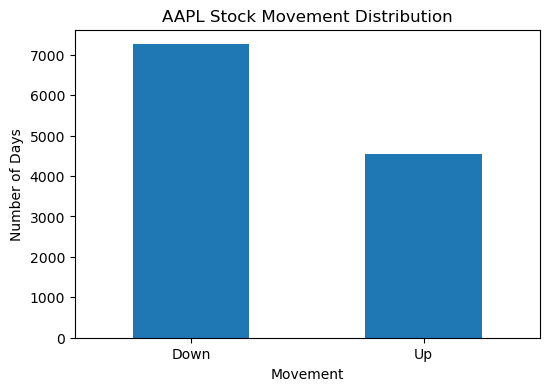

In [8]:
print("Stock Movement Distribution:")
print(y.value_counts())

plt.figure(figsize=(6, 4))
y.value_counts().sort_index().plot(kind="bar")
plt.xlabel("Movement")
plt.ylabel("Number of Days")
plt.title("AAPL Stock Movement Distribution")
plt.xticks([0, 1], ["Down", "Up"], rotation=0)
plt.show()

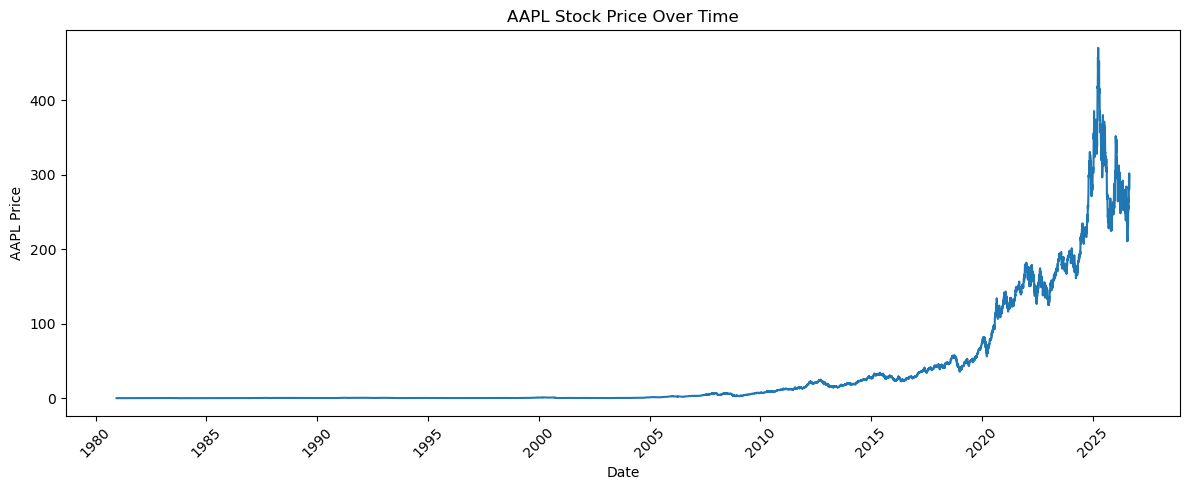

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(data["Date"], data["AAPL"])

plt.xlabel("Date")
plt.ylabel("AAPL Price")
plt.title("AAPL Stock Price Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

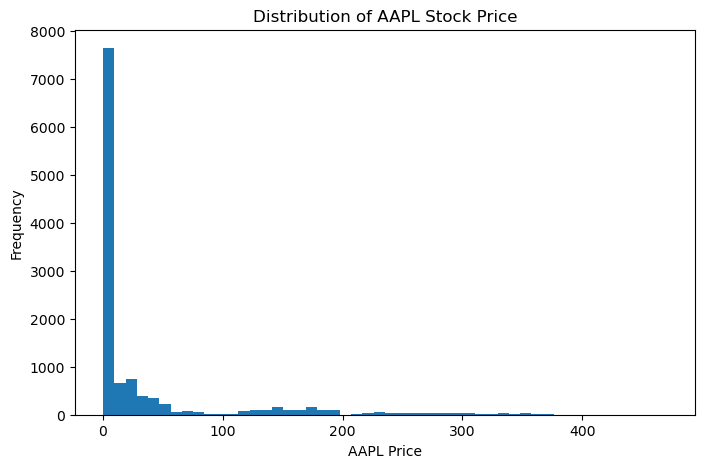

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(data["AAPL"], bins=50)

plt.xlabel("AAPL Price")
plt.ylabel("Frequency")
plt.title("Distribution of AAPL Stock Price")

plt.show()

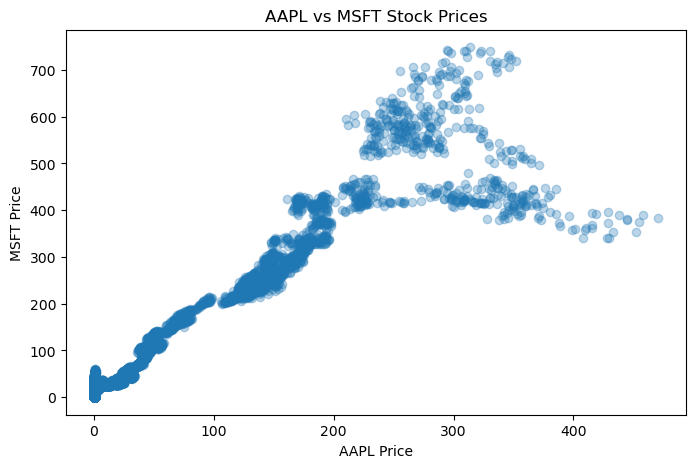

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(data["AAPL"], data["MSFT"], alpha=0.3)

plt.xlabel("AAPL Price")
plt.ylabel("MSFT Price")
plt.title("AAPL vs MSFT Stock Prices")

plt.show()

In [13]:
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Validation/Test data:", X_test.shape)

print("\nTraining period:")
print(data["Date"].iloc[0], "to", data["Date"].iloc[split_index - 1])

print("\nValidation/Test period:")
print(data["Date"].iloc[split_index], "to", data["Date"].iloc[-1])

Training data: (9448, 10)
Validation/Test data: (2363, 10)

Training period:
1980-12-12 00:00:00 to 2017-07-13 00:00:00

Validation/Test period:
2017-07-14 00:00:00 to 2026-08-27 00:00:00


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


In [15]:
model = LogisticRegression(max_iter=1000)

print("Logistic Regression model created")

Logistic Regression model created


In [16]:
model.fit(X_train_scaled, y_train)

print("Model training completed successfully")

Model training completed successfully


In [17]:
y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully")

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

print("\nFirst 20 Predicted Values:")
print(y_pred[:20])

Predictions generated successfully

First 20 Actual Values:
[1 1 1 0 0 1 1 1 0 0 0 1 1 0 1 1 1 1 0 1]

First 20 Predicted Values:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0]


In [18]:
results = pd.DataFrame({
    "Date": data["Date"].iloc[split_index:].values,
    "Actual_Movement": y_test.values,
    "Predicted_Movement": y_pred
})

results["Actual_Label"] = results["Actual_Movement"].map({
    0: "Down",
    1: "Up"
})

results["Predicted_Label"] = results["Predicted_Movement"].map({
    0: "Down",
    1: "Up"
})

display(results.head(20))

,Date,Actual_Movement,Predicted_Movement,Actual_Label,Predicted_Label
0,2017-07-14,1,1,Up,Up
1,2017-07-17,1,1,Up,Up
2,2017-07-18,1,1,Up,Up
3,2017-07-19,0,1,Down,Up
4,2017-07-20,0,1,Down,Up
5,2017-07-21,1,1,Up,Up
6,2017-07-24,1,1,Up,Up
7,2017-07-25,1,1,Up,Up
8,2017-07-26,0,1,Down,Up
9,2017-07-27,0,1,Down,Up


In [19]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:")
print(accuracy * 100, "%")

Model Accuracy:
51.883199322894626 %


In [20]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[383 731]
 [406 843]]


In [21]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Down", "Up"]
))

Classification Report:
              precision    recall  f1-score   support

        Down       0.49      0.34      0.40      1114
          Up       0.54      0.67      0.60      1249

    accuracy                           0.52      2363
   macro avg       0.51      0.51      0.50      2363
weighted avg       0.51      0.52      0.51      2363



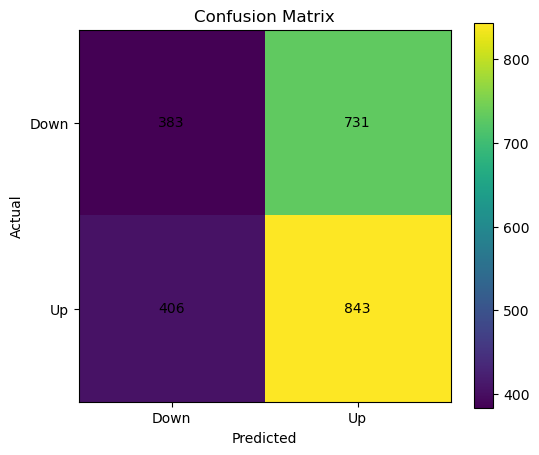

In [22]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Down", "Up"])
plt.yticks([0, 1], ["Down", "Up"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

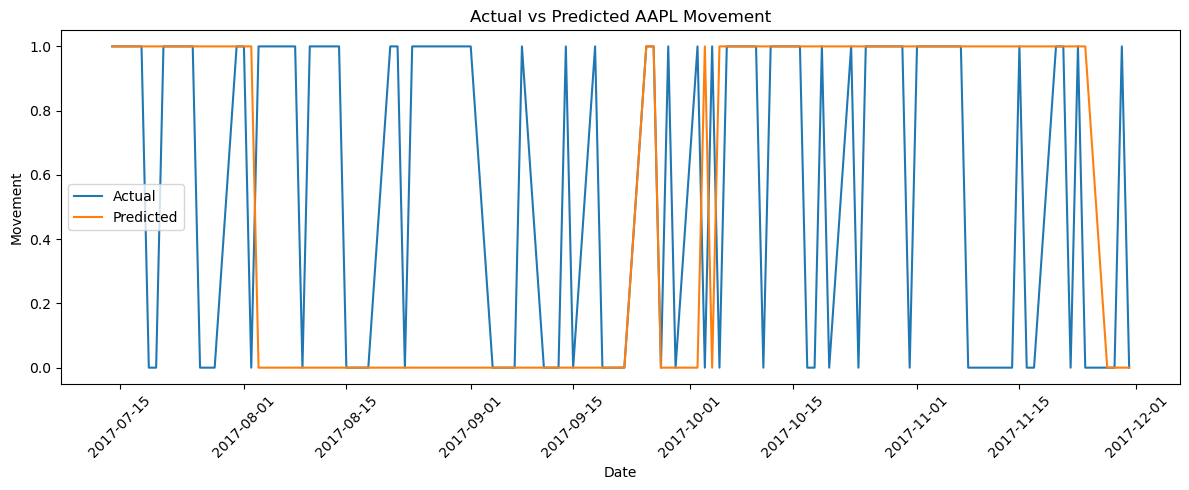

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    results["Date"].iloc[:100],
    results["Actual_Movement"].iloc[:100],
    label="Actual"
)

plt.plot(
    results["Date"].iloc[:100],
    results["Predicted_Movement"].iloc[:100],
    label="Predicted"
)

plt.xlabel("Date")
plt.ylabel("Movement")
plt.title("Actual vs Predicted AAPL Movement")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_[0]
})

feature_importance["Absolute_Importance"] = abs(
    feature_importance["Coefficient"]
)

feature_importance = feature_importance.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(feature_importance)

,Feature,Coefficient,Absolute_Importance
8,SPB25SIP,0.400726,0.400726
5,MSFT,0.391467,0.391467
6,SAMSUNG,0.325343,0.325343
0,AAPL,-0.249383,0.249383
7,SBUX,-0.210134,0.210134
1,ADANIPORTS,-0.195649,0.195649
3,HSI,-0.135492,0.135492
9,TATAMOTORS,0.114647,0.114647
2,GSPC,-0.111073,0.111073
4,IBM,-0.001940,0.001940


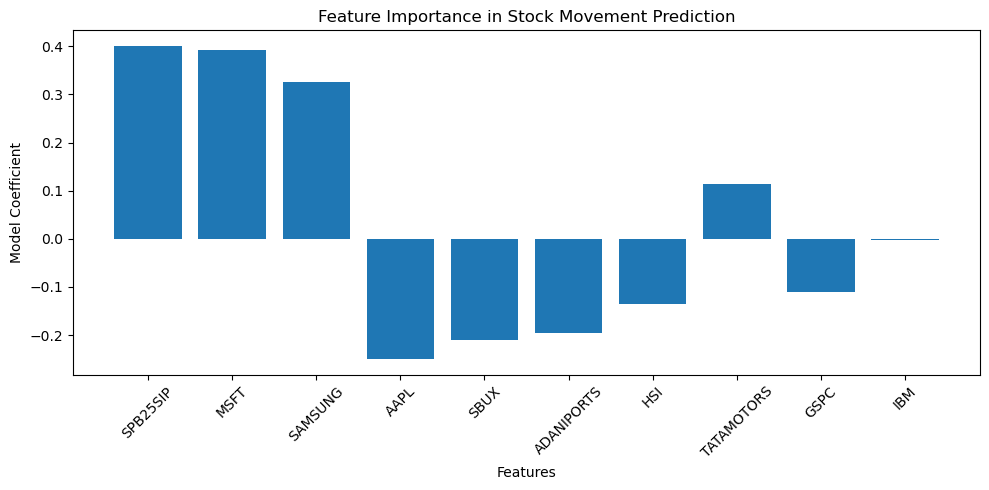

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Coefficient"]
)

plt.xlabel("Features")
plt.ylabel("Model Coefficient")
plt.title("Feature Importance in Stock Movement Prediction")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
import joblib

joblib.dump(model, "stock_movement_model.pkl")
joblib.dump(scaler, "stock_movement_scaler.pkl")

print("Model saved as stock_movement_model.pkl")
print("Scaler saved as stock_movement_scaler.pkl")

Model saved as stock_movement_model.pkl
Scaler saved as stock_movement_scaler.pkl


In [27]:
loaded_model = joblib.load("stock_movement_model.pkl")
loaded_scaler = joblib.load("stock_movement_scaler.pkl")

sample = X_test.iloc[[0]]

sample_scaled = loaded_scaler.transform(sample)

prediction = loaded_model.predict(sample_scaled)[0]

if prediction == 1:
    print("Predicted Stock Movement: UP")
else:
    print("Predicted Stock Movement: DOWN")

Predicted Stock Movement: UP


In [28]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Print Results
print("========== MODEL EVALUATION ==========")

print("\nConfusion Matrix:")
print(cm)

print("\nAccuracy:")
print(accuracy * 100, "%")

print("\nPrecision:")
print(precision * 100, "%")

print("\nRecall:")
print(recall * 100, "%")

print("\nF1 Score:")
print(f1 * 100, "%")

print("\n=======================================")

========== MODEL EVALUATION ==========

Confusion Matrix:
[[383 731]
 [406 843]]

Accuracy:
51.883199322894626 %

Precision:
53.557814485387546 %

Recall:
67.49399519615693 %

F1 Score:
59.723698193411266 %



Dataset Shape: (11812, 11)
Features created successfully
New Dataset Shape: (11792, 32)

Number of Features: 20
Input Shape: (11792, 20)
Target Shape: (11792,)

Training Samples: 9433
Testing Samples: 2359

Random Forest model created
Model training completed successfully

Prediction completed successfully


       FINAL MODEL EVALUATION

Confusion Matrix:
[[1096   17]
 [1218   28]]

Accuracy  : 47.65 %
Precision : 62.22 %
Recall    : 2.25 %
F1 Score  : 4.34 %


Classification Report:
              precision    recall  f1-score   support

        Down       0.47      0.98      0.64      1113
          Up       0.62      0.02      0.04      1246

    accuracy                           0.48      2359
   macro avg       0.55      0.50      0.34      2359
weighted avg       0.55      0.48      0.32      2359


Prediction Results:


,Date,Actual,Predicted,Actual_Label,Predicted_Label
0,2017-07-20,0,1,DOWN,UP
1,2017-07-21,1,1,UP,UP
2,2017-07-24,1,1,UP,UP
3,2017-07-25,1,1,UP,UP
4,2017-07-26,0,1,DOWN,UP
5,2017-07-27,0,1,DOWN,UP
6,2017-07-28,0,1,DOWN,UP
7,2017-07-31,1,1,UP,UP
8,2017-08-01,1,1,UP,UP
9,2017-08-02,0,0,DOWN,DOWN



Feature Importance:


,Feature,Importance
4,AAPL_Lag3,0.070840
8,MA20,0.070115
7,MA10,0.069494
6,MA5,0.068193
3,AAPL_Lag2,0.063337
1,AAPL_Return,0.062939
0,AAPL,0.054884
2,AAPL_Lag1,0.054140
15,MSFT_Return,0.045050
9,MA5_MA20,0.044639


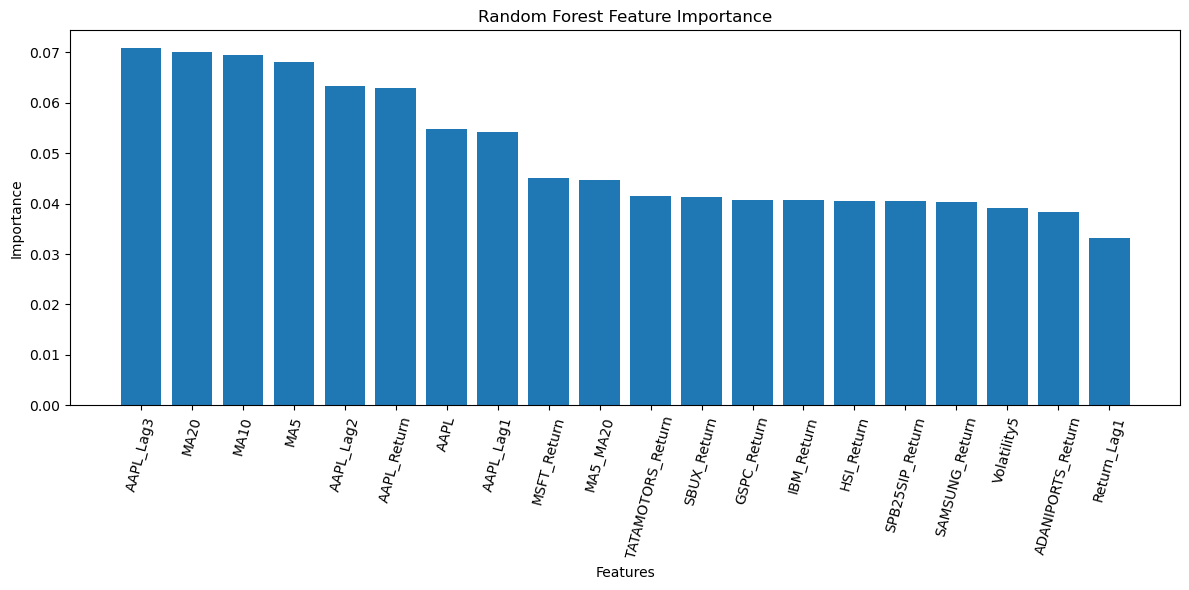

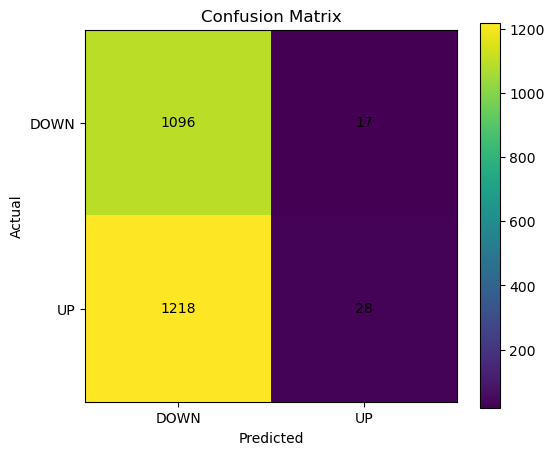


Model saved as:
stock_movement_random_forest.pkl


In [30]:
# ============================================================
# STOCK PRICE MOVEMENT PREDICTION - IMPROVED MODEL
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Load Dataset
# ------------------------------------------------------------

data = pd.read_csv(r"C:\Users\vivek\Downloads\stock_data_wide_filled.csv")

data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

data = data.drop_duplicates()
data = data.dropna(subset=["Date"])
data = data.sort_values("Date").reset_index(drop=True)

# Fill missing numerical values
numeric_columns = data.select_dtypes(include=np.number).columns
data[numeric_columns] = data[numeric_columns].ffill()

data = data.dropna().reset_index(drop=True)

print("Dataset Shape:", data.shape)


# ------------------------------------------------------------
# 2. Create Target Variable
# ------------------------------------------------------------

# Next day's AAPL price
data["Next_AAPL"] = data["AAPL"].shift(-1)

# 1 = UP
# 0 = DOWN
data["Movement"] = (data["Next_AAPL"] > data["AAPL"]).astype(int)


# ------------------------------------------------------------
# 3. Create Additional Features
# ------------------------------------------------------------

# AAPL percentage changes
data["AAPL_Return"] = data["AAPL"].pct_change()

# Previous-day AAPL price
data["AAPL_Lag1"] = data["AAPL"].shift(1)

# Two-day lag
data["AAPL_Lag2"] = data["AAPL"].shift(2)

# Three-day lag
data["AAPL_Lag3"] = data["AAPL"].shift(3)

# Previous-day return
data["Return_Lag1"] = data["AAPL_Return"].shift(1)

# Moving averages
data["MA5"] = data["AAPL"].rolling(window=5).mean()
data["MA10"] = data["AAPL"].rolling(window=10).mean()
data["MA20"] = data["AAPL"].rolling(window=20).mean()

# Moving-average difference
data["MA5_MA20"] = data["MA5"] - data["MA20"]

# Volatility
data["Volatility5"] = data["AAPL_Return"].rolling(window=5).std()

# Other market returns
other_columns = [
    "ADANIPORTS",
    "GSPC",
    "HSI",
    "IBM",
    "MSFT",
    "SAMSUNG",
    "SBUX",
    "SPB25SIP",
    "TATAMOTORS"
]

for column in other_columns:
    data[column + "_Return"] = data[column].pct_change()


# Remove rows created by lagging/rolling
data = data.dropna().reset_index(drop=True)

print("Features created successfully")
print("New Dataset Shape:", data.shape)


# ------------------------------------------------------------
# 4. Feature Selection
# ------------------------------------------------------------

features = [
    "AAPL",
    "AAPL_Return",
    "AAPL_Lag1",
    "AAPL_Lag2",
    "AAPL_Lag3",
    "Return_Lag1",
    "MA5",
    "MA10",
    "MA20",
    "MA5_MA20",
    "Volatility5",

    "ADANIPORTS_Return",
    "GSPC_Return",
    "HSI_Return",
    "IBM_Return",
    "MSFT_Return",
    "SAMSUNG_Return",
    "SBUX_Return",
    "SPB25SIP_Return",
    "TATAMOTORS_Return"
]

X = data[features]
y = data["Movement"]

print("\nNumber of Features:", len(features))
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)


# ------------------------------------------------------------
# 5. Train-Test Split
# ------------------------------------------------------------

# IMPORTANT:
# Do not shuffle stock time-series data.

split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ------------------------------------------------------------
# 6. Build Random Forest Model
# ------------------------------------------------------------

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    class_weight="balanced"
)

print("\nRandom Forest model created")


# ------------------------------------------------------------
# 7. Model Training
# ------------------------------------------------------------

model.fit(X_train, y_train)

print("Model training completed successfully")


# ------------------------------------------------------------
# 8. Prediction
# ------------------------------------------------------------

y_pred = model.predict(X_test)

print("\nPrediction completed successfully")


# ------------------------------------------------------------
# 9. Final Evaluation
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


# ------------------------------------------------------------
# 10. Print Final Results
# ------------------------------------------------------------

print("\n")
print("=" * 50)
print("       FINAL MODEL EVALUATION")
print("=" * 50)

print("\nConfusion Matrix:")
print(cm)

print("\nAccuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision * 100, 2), "%")
print("Recall    :", round(recall * 100, 2), "%")
print("F1 Score  :", round(f1 * 100, 2), "%")

print("\n" + "=" * 50)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Down", "Up"],
        zero_division=0
    )
)


# ------------------------------------------------------------
# 11. Actual vs Predicted
# ------------------------------------------------------------

results = pd.DataFrame({
    "Date": data["Date"].iloc[split_index:].values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Actual_Label"] = results["Actual"].map({
    0: "DOWN",
    1: "UP"
})

results["Predicted_Label"] = results["Predicted"].map({
    0: "DOWN",
    1: "UP"
})

print("\nPrediction Results:")
display(results.head(20))


# ------------------------------------------------------------
# 12. Feature Importance
# ------------------------------------------------------------

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\nFeature Importance:")
display(importance)


# ------------------------------------------------------------
# 13. Feature Importance Graph
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Confusion Matrix Graph
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["DOWN", "UP"])
plt.yticks([0, 1], ["DOWN", "UP"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()


# ------------------------------------------------------------
# 15. Save Model
# ------------------------------------------------------------

import joblib

joblib.dump(model, "stock_movement_random_forest.pkl")

print("\nModel saved as:")
print("stock_movement_random_forest.pkl")

Dataset loaded successfully
Original Dataset Shape: (11812, 11)

First 5 Rows:


,Date,AAPL,ADANIPORTS,GSPC,HSI,IBM,MSFT,SAMSUNG,SBUX,SPB25SIP,TATAMOTORS
0,1980-12-12,0.13,3043.734184,339.393327,273.513801,85.343087,0.019408,315.411013,0.177212,5.136859,486.628833
1,1980-12-15,0.12,2978.152580,337.406152,269.567404,84.897857,0.019736,320.995920,0.176769,5.103685,507.556052
2,1980-12-16,0.11,2975.394865,338.185139,272.741338,84.450065,0.019483,317.177071,0.171086,5.114073,514.831896
3,1980-12-17,0.12,3119.359296,331.016915,274.418650,83.599729,0.019457,308.972906,0.178369,5.107420,535.898290
4,1980-12-18,0.12,3092.607420,333.717337,278.338244,82.592358,0.019398,309.114081,0.185337,5.010459,545.372373



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11812 entries, 0 to 11811
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        11812 non-null  object 
 1   AAPL        11812 non-null  float64
 2   ADANIPORTS  11812 non-null  float64
 3   GSPC        11812 non-null  float64
 4   HSI         11812 non-null  float64
 5   IBM         11812 non-null  float64
 6   MSFT        11812 non-null  float64
 7   SAMSUNG     11812 non-null  float64
 8   SBUX        11812 non-null  float64
 9   SPB25SIP    11812 non-null  float64
 10  TATAMOTORS  11812 non-null  float64
dtypes: float64(10), object(1)
memory usage: 1015.2+ KB

Missing Values:
Date          0
AAPL          0
ADANIPORTS    0
GSPC          0
HSI           0
IBM           0
MSFT          0
SAMSUNG       0
SBUX          0
SPB25SIP      0
TATAMOTORS    0
dtype: int64

Statistical Summary:


,AAPL,ADANIPORTS,GSPC,HSI,IBM,MSFT,SAMSUNG,SBUX,SPB25SIP,TATAMOTORS
count,11812.000000,11812.000000,11812.000000,1.181200e+04,11812.000000,11812.000000,11812.000000,11812.000000,11812.000000,11812.000000
mean,34.638033,597.235759,1973.113664,5.241861e+07,101.769843,72.693594,18012.936548,30.422618,1236.622109,469.043379
std,72.709019,710.236191,1711.257718,1.267568e+08,49.052516,129.890864,22141.981754,42.919777,1768.740321,241.336923
min,0.050000,20.909968,290.692392,2.621258e+02,35.256799,0.019033,158.419340,0.163305,4.926243,58.800000
25%,0.310000,124.353598,1000.479458,1.685842e+04,64.037164,2.453125,1406.844097,1.427031,36.168151,294.912500
50%,0.820000,310.900000,1461.320080,4.520057e+05,91.249873,26.740000,8750.000000,10.446218,260.130961,450.009571
75%,26.097500,758.093198,2079.449951,3.122633e+07,134.147133,47.468750,27040.000000,47.666544,1919.082500,615.833675
max,470.399760,3784.722147,8261.412024,8.582024e+08,379.383078,748.407790,91000.000000,230.890497,7564.320834,1463.512664



After Cleaning:
Dataset Shape: (11812, 11)

Feature Engineering Completed
Final Dataset Shape: (11792, 34)

Number of Features: 22
X Shape: (11792, 22)
y Shape: (11792,)

Training Samples: 9433
Testing Samples: 2359

Feature scaling completed


                 MODEL TRAINING

Training: Logistic Regression
Completed: Logistic Regression

Training: SVM
Completed: SVM

Training: Random Forest
Completed: Random Forest

Training: Extra Trees
Completed: Extra Trees

Training: Gradient Boosting
Completed: Gradient Boosting

Training: Hist Gradient Boosting
Completed: Hist Gradient Boosting


                 MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,52.86%,52.84%,99.92%,69.13%
1,Extra Trees,53.88%,54.13%,83.07%,65.55%
2,Hist Gradient Boosting,51.08%,54.28%,46.79%,50.26%
3,Gradient Boosting,48.20%,55.22%,10.19%,17.21%
4,SVM,47.86%,59.09%,4.17%,7.80%
5,Random Forest,47.39%,52.58%,4.09%,7.59%




BEST MODEL SELECTED

Best Model: Logistic Regression
Reason: Highest F1 Score among the tested models


             FINAL BEST MODEL EVALUATION

Selected Model:
Logistic Regression

Confusion Matrix:
[[   2 1111]
 [   1 1245]]

Accuracy  : 52.86 %
Precision : 52.84 %
Recall    : 99.92 %
F1 Score  : 69.13 %

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.67      0.00      0.00      1113
          UP       0.53      1.00      0.69      1246

    accuracy                           0.53      2359
   macro avg       0.60      0.50      0.35      2359
weighted avg       0.59      0.53      0.37      2359



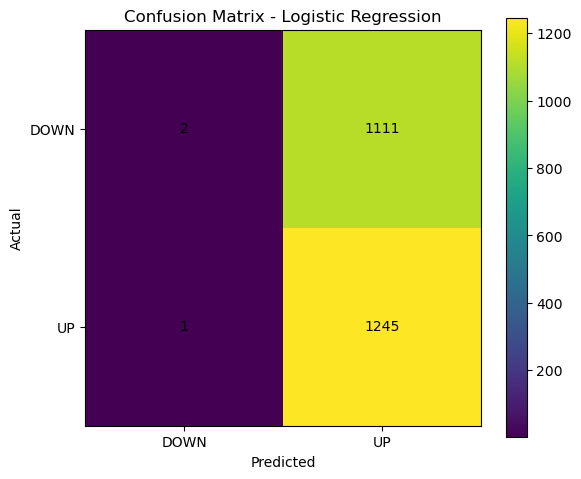

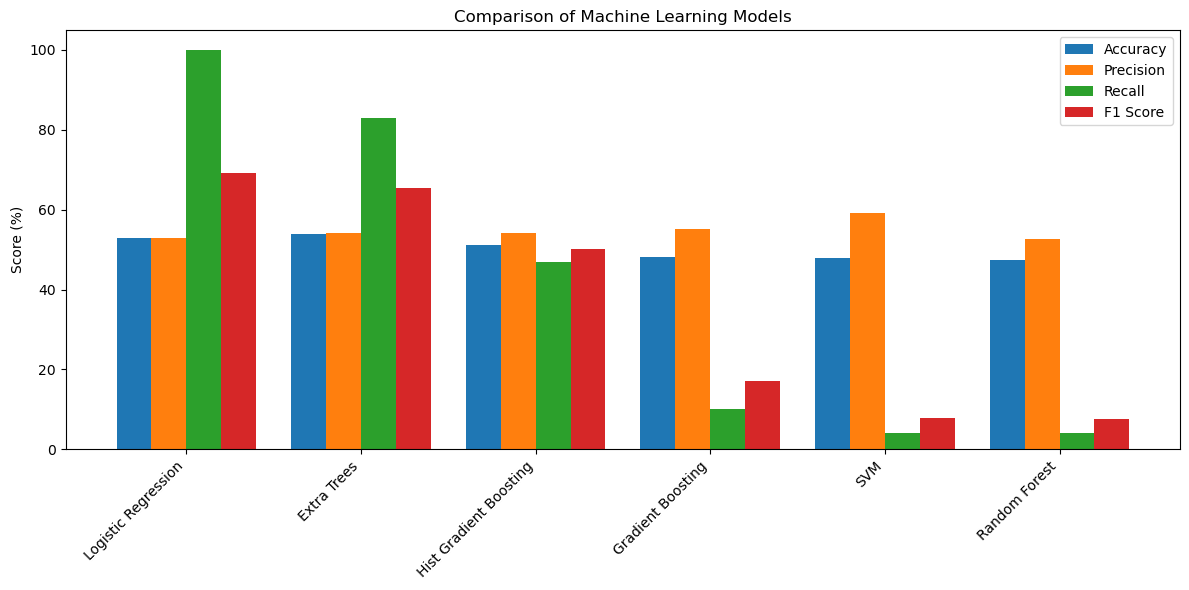



MODEL SAVING

Best model saved as:
best_stock_movement_model.pkl

Scaler saved as:
stock_movement_scaler.pkl

Feature list saved as:
stock_movement_features.pkl

Process completed successfully!


In [32]:
# ============================================================
# STOCK PRICE MOVEMENT PREDICTION
# MULTIPLE MODEL TRAINING AND BEST MODEL SELECTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "8"

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


# ============================================================
# 1. DATA COLLECTION
# ============================================================

file_path = r"C:\Users\vivek\Downloads\stock_data_wide_filled.csv"

data = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Original Dataset Shape:", data.shape)


# ============================================================
# 2. DATA INSPECTION
# ============================================================

print("\nFirst 5 Rows:")
display(data.head())

print("\nDataset Information:")
data.info()

print("\nMissing Values:")
print(data.isnull().sum())

print("\nStatistical Summary:")
display(data.describe())


# ============================================================
# 3. DATA CLEANING
# ============================================================

data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

data = data.drop_duplicates()

data = data.dropna(subset=["Date"])

data = data.sort_values("Date").reset_index(drop=True)

numeric_columns = data.select_dtypes(include=np.number).columns

data[numeric_columns] = data[numeric_columns].ffill()

data = data.dropna().reset_index(drop=True)

print("\nAfter Cleaning:")
print("Dataset Shape:", data.shape)


# ============================================================
# 4. TARGET CREATION
# ============================================================

# Next day's AAPL price
data["Next_AAPL"] = data["AAPL"].shift(-1)

# 1 = UP
# 0 = DOWN
data["Movement"] = (
    data["Next_AAPL"] > data["AAPL"]
).astype(int)


# ============================================================
# 5. FEATURE ENGINEERING
# ============================================================

# AAPL return
data["AAPL_Return"] = data["AAPL"].pct_change()

# Lag features
data["AAPL_Lag1"] = data["AAPL"].shift(1)
data["AAPL_Lag2"] = data["AAPL"].shift(2)
data["AAPL_Lag3"] = data["AAPL"].shift(3)

# Return lag
data["Return_Lag1"] = data["AAPL_Return"].shift(1)

# Moving averages
data["MA5"] = data["AAPL"].rolling(5).mean()
data["MA10"] = data["AAPL"].rolling(10).mean()
data["MA20"] = data["AAPL"].rolling(20).mean()

# Moving average difference
data["MA5_MA20"] = data["MA5"] - data["MA20"]

# Volatility
data["Volatility5"] = (
    data["AAPL_Return"].rolling(5).std()
)

# Momentum
data["Momentum5"] = (
    data["AAPL"] - data["AAPL"].shift(5)
)

data["Momentum10"] = (
    data["AAPL"] - data["AAPL"].shift(10)
)


# ============================================================
# 6. OTHER MARKET RETURNS
# ============================================================

market_columns = [
    "ADANIPORTS",
    "GSPC",
    "HSI",
    "IBM",
    "MSFT",
    "SAMSUNG",
    "SBUX",
    "SPB25SIP",
    "TATAMOTORS"
]

for column in market_columns:

    data[column + "_Return"] = (
        data[column].pct_change()
    )


# Remove rows generated by lag/rolling operations
data = data.dropna().reset_index(drop=True)

print("\nFeature Engineering Completed")
print("Final Dataset Shape:", data.shape)


# ============================================================
# 7. FEATURE SELECTION
# ============================================================

features = [

    "AAPL",
    "AAPL_Return",

    "AAPL_Lag1",
    "AAPL_Lag2",
    "AAPL_Lag3",

    "Return_Lag1",

    "MA5",
    "MA10",
    "MA20",

    "MA5_MA20",

    "Volatility5",

    "Momentum5",
    "Momentum10",

    "ADANIPORTS_Return",
    "GSPC_Return",
    "HSI_Return",
    "IBM_Return",
    "MSFT_Return",
    "SAMSUNG_Return",
    "SBUX_Return",
    "SPB25SIP_Return",
    "TATAMOTORS_Return"
]

X = data[features]

y = data["Movement"]

print("\nNumber of Features:", len(features))

print("X Shape:", X.shape)

print("y Shape:", y.shape)


# ============================================================
# 8. TRAIN-TEST SPLIT
# ============================================================

# Chronological split
# First 80% = Training
# Last 20% = Testing

split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ============================================================
# 9. SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed")


# ============================================================
# 10. DEFINE MODELS
# ============================================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=2000
        ),

    "SVM":
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features="sqrt",
            random_state=42,
            class_weight="balanced"
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            class_weight="balanced"
        ),

    "Gradient Boosting":
        GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),

    "Hist Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        )
}


# ============================================================
# 11. TRAIN ALL MODELS
# ============================================================

results = []

trained_models = {}

predictions = {}

print("\n")
print("=" * 70)
print("                 MODEL TRAINING")
print("=" * 70)

for name, model in models.items():

    print("\nTraining:", name)

    # Models that need scaled data
    if name in ["Logistic Regression", "SVM"]:

        model.fit(
            X_train_scaled,
            y_train
        )

        prediction = model.predict(
            X_test_scaled
        )

    else:

        model.fit(
            X_train,
            y_train
        )

        prediction = model.predict(
            X_test
        )

    # Store model
    trained_models[name] = model

    # Store predictions
    predictions[name] = prediction

    # Calculate metrics
    accuracy = accuracy_score(
        y_test,
        prediction
    )

    precision = precision_score(
        y_test,
        prediction,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    results.append({

        "Model": name,

        "Accuracy": accuracy * 100,

        "Precision": precision * 100,

        "Recall": recall * 100,

        "F1 Score": f1 * 100
    })

    print("Completed:", name)


# ============================================================
# 12. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n")
print("=" * 70)
print("                 MODEL COMPARISON")
print("=" * 70)

display(
    results_df.style.format({
        "Accuracy": "{:.2f}%",
        "Precision": "{:.2f}%",
        "Recall": "{:.2f}%",
        "F1 Score": "{:.2f}%"
    })
)


# ============================================================
# 13. SELECT BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[
    best_model_name
]

best_prediction = predictions[
    best_model_name
]

print("\n")
print("=" * 70)

print("BEST MODEL SELECTED")

print("=" * 70)

print("\nBest Model:", best_model_name)

print(
    "Reason: Highest F1 Score among the tested models"
)


# ============================================================
# 14. FINAL EVALUATION OF BEST MODEL
# ============================================================

best_cm = confusion_matrix(
    y_test,
    best_prediction
)

best_accuracy = accuracy_score(
    y_test,
    best_prediction
)

best_precision = precision_score(
    y_test,
    best_prediction,
    zero_division=0
)

best_recall = recall_score(
    y_test,
    best_prediction,
    zero_division=0
)

best_f1 = f1_score(
    y_test,
    best_prediction,
    zero_division=0
)


print("\n")
print("=" * 70)
print("             FINAL BEST MODEL EVALUATION")
print("=" * 70)

print("\nSelected Model:")
print(best_model_name)

print("\nConfusion Matrix:")
print(best_cm)

print(
    "\nAccuracy  :",
    round(best_accuracy * 100, 2),
    "%"
)

print(
    "Precision :",
    round(best_precision * 100, 2),
    "%"
)

print(
    "Recall    :",
    round(best_recall * 100, 2),
    "%"
)

print(
    "F1 Score  :",
    round(best_f1 * 100, 2),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_prediction,
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)


# ============================================================
# 15. CONFUSION MATRIX VISUALIZATION
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(best_cm)

plt.title(
    "Confusion Matrix - " + best_model_name
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["DOWN", "UP"]
)

plt.yticks(
    [0, 1],
    ["DOWN", "UP"]
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            best_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.show()


# ============================================================
# 16. MODEL COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(12, 6))

x = np.arange(len(results_df))

width = 0.2

plt.bar(
    x - 1.5 * width,
    results_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x - 0.5 * width,
    results_df["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x + 0.5 * width,
    results_df["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + 1.5 * width,
    results_df["F1 Score"],
    width,
    label="F1 Score"
)

plt.xticks(
    x,
    results_df["Model"],
    rotation=45,
    ha="right"
)

plt.ylabel("Score (%)")

plt.title("Comparison of Machine Learning Models")

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 17. SAVE BEST MODEL
# ============================================================

joblib.dump(
    best_model,
    "best_stock_movement_model.pkl"
)

joblib.dump(
    scaler,
    "stock_movement_scaler.pkl"
)

joblib.dump(
    features,
    "stock_movement_features.pkl"
)

print("\n")
print("=" * 70)

print("MODEL SAVING")

print("=" * 70)

print(
    "\nBest model saved as:"
)

print(
    "best_stock_movement_model.pkl"
)

print(
    "\nScaler saved as:"
)

print(
    "stock_movement_scaler.pkl"
)

print(
    "\nFeature list saved as:"
)

print(
    "stock_movement_features.pkl"
)

print("\nProcess completed successfully!")

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predictions from selected model
final_predictions = best_model.predict(X_test_scaled if best_model_name in ["Logistic Regression", "SVM"] else X_test)

# Calculate metrics
final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(y_test, final_predictions, zero_division=0)
final_recall = recall_score(y_test, final_predictions, zero_division=0)
final_f1 = f1_score(y_test, final_predictions, zero_division=0)

print("\n========================================")
print("FINAL SELECTED MODEL")
print("========================================")

print("Selected Model:", best_model_name)
print("Accuracy:", f"{final_accuracy * 100:.2f}%")
print("Precision:", f"{final_precision * 100:.2f}%")
print("Recall:", f"{final_recall * 100:.2f}%")
print("F1 Score:", f"{final_f1 * 100:.2f}%")

print("========================================")


FINAL SELECTED MODEL
Selected Model: Logistic Regression
Accuracy: 52.86%
Precision: 52.84%
Recall: 99.92%
F1 Score: 69.13%
